# Versión A — Redes Neuronales: Pipeline Completo
## Evaluación, Optimización, Regularización e Interpretabilidad
### Ingeniería del Conocimiento (ISO56B) — Sesiones 05, 06 y 07
### UNCP — Facultad de Ingeniería de Sistemas
### Docente: Msc. Jaime Antonio Huaytalla Pariona | Semestre 2026-II

---

**Enfoque:** Redes Neuronales Densas (MLP) aplicadas a datos tabulares.

**Dataset:** Breast Cancer Wisconsin — clasificación binaria (maligno vs benigno) con 30 características clínicas.

**Bloques temáticos:**
1. Datos y modelo base
2. Evaluación — de lo simple a lo riguroso
3. Optimización y regularización
4. Interpretabilidad y explicabilidad

> 🧠 Este notebook demuestra el flujo de trabajo completo de un proyecto de clasificación con redes neuronales densas, desde la exploración de datos hasta la explicación de las predicciones del modelo.

In [1]:
# ============================================================
# CONFIGURACIÓN INICIAL
# ============================================================
# Instalar librerías de interpretabilidad (solo la primera vez)
!pip install -q shap

# --- Librerías principales ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# --- TensorFlow / Keras ---
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers, callbacks

# --- Scikit-learn (preprocesamiento y métricas) ---
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    accuracy_score, f1_score
)
from sklearn.inspection import permutation_importance

# --- Interpretabilidad ---
import shap

# --- Reproducibilidad ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- Estilo visual ---
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print(f"TensorFlow: {tf.__version__}")
print(f"NumPy:      {np.__version__}")
print(f"GPU:        {tf.config.list_physical_devices('GPU') or 'No disponible (CPU)'}")

TensorFlow: 2.21.0
NumPy:      2.1.3
GPU:        [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## BLOQUE 1 — Datos y Exploración

El dataset **Breast Cancer Wisconsin** contiene 569 muestras de biopsias de tumores de mama, cada una descrita por 30 características numéricas extraídas de imágenes digitalizadas. La tarea es clasificar cada tumor como **maligno** (0) o **benigno** (1).

In [2]:
# ============================================================
# CARGA DEL DATASET
# ============================================================
# load_breast_cancer() viene integrado en sklearn — no requiere descarga
data = load_breast_cancer()

# Convertimos a DataFrame para facilitar la exploración
df = pd.DataFrame(data.data, columns=data.feature_names)
df['diagnostico'] = data.target  # 0 = maligno, 1 = benigno

print("=" * 60)
print("INFORMACIÓN DEL DATASET")
print("=" * 60)
print(f"Muestras totales:  {df.shape[0]}")
print(f"Características:   {df.shape[1] - 1}")
print(f"Clases:            {dict(zip(data.target_names, np.bincount(data.target)))}")
print(f"Valores nulos:     {df.isnull().sum().sum()}")
print(f"\nPrimeras 5 filas:")
df.head()

INFORMACIÓN DEL DATASET
Muestras totales:  569
Características:   30
Clases:            {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Valores nulos:     0

Primeras 5 filas:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


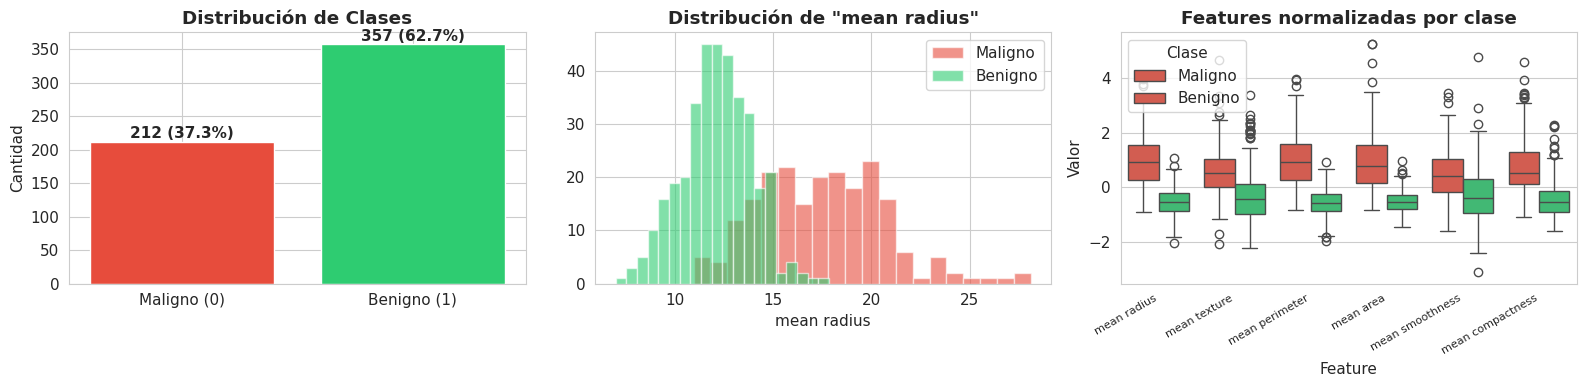

In [3]:
# ============================================================
# ANÁLISIS EXPLORATORIO DE DATOS (EDA)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# --- 1. Distribución de clases ---
counts = df['diagnostico'].value_counts()
colors = ['#e74c3c', '#2ecc71']  # rojo=maligno, verde=benigno
axes[0].bar(['Maligno (0)', 'Benigno (1)'], [counts[0], counts[1]], color=colors)
axes[0].set_title('Distribución de Clases', fontweight='bold')
axes[0].set_ylabel('Cantidad')
for i, v in enumerate([counts[0], counts[1]]):
    axes[0].text(i, v + 5, f'{v} ({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')

# --- 2. Distribución de una característica clave ---
# 'mean radius' es una de las features más discriminativas
for label, color, name in [(0, '#e74c3c', 'Maligno'), (1, '#2ecc71', 'Benigno')]:
    subset = df[df['diagnostico'] == label]['mean radius']
    axes[1].hist(subset, bins=20, alpha=0.6, color=color, label=name, edgecolor='white')
axes[1].set_title('Distribución de "mean radius"', fontweight='bold')
axes[1].set_xlabel('mean radius')
axes[1].legend()

# --- 3. Boxplot de las 6 features más importantes ---
top_features = ['mean radius', 'mean texture', 'mean perimeter',
                'mean area', 'mean smoothness', 'mean compactness']
# Normalizamos para que se vean juntas en el boxplot
df_norm = (df[top_features] - df[top_features].mean()) / df[top_features].std()
df_norm['diagnostico'] = df['diagnostico']
df_melted = df_norm.melt(id_vars='diagnostico', var_name='Feature', value_name='Valor')
sns.boxplot(data=df_melted, x='Feature', y='Valor', hue='diagnostico',
            palette={0: '#e74c3c', 1: '#2ecc71'}, ax=axes[2])
axes[2].set_title('Features normalizadas por clase', fontweight='bold')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=30, ha='right', fontsize=8)
axes[2].legend(title='Clase', labels=['Maligno', 'Benigno'])

plt.tight_layout()
plt.show()

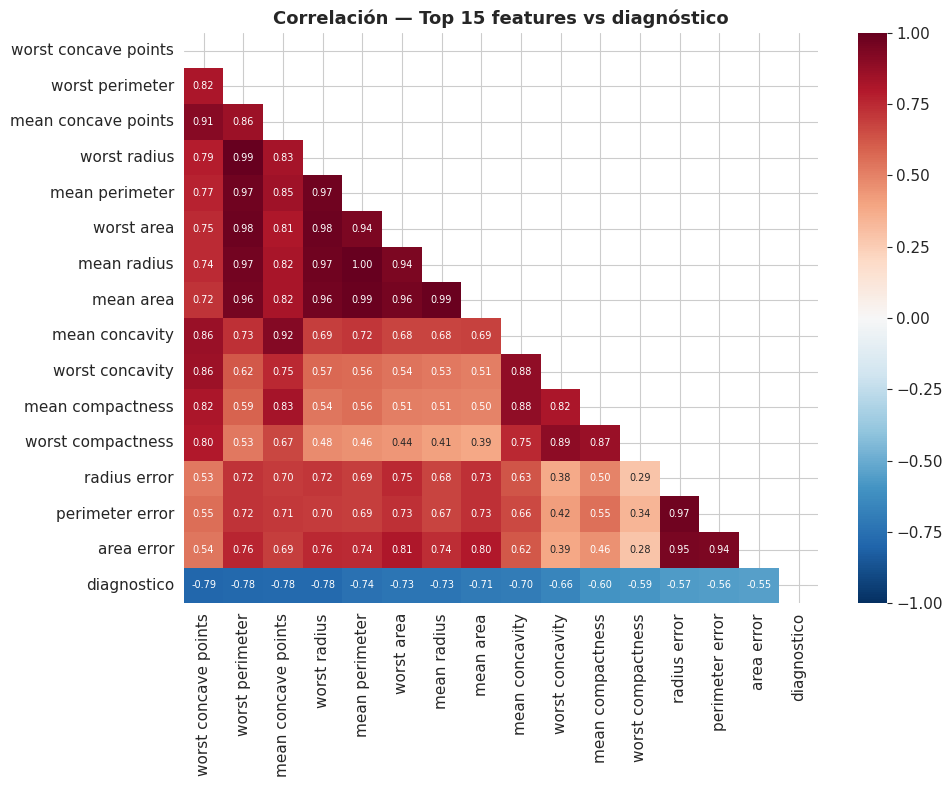


Top 10 features más correlacionadas con el diagnóstico:
   1. worst concave points           |r| = 0.7936
   2. worst perimeter                |r| = 0.7829
   3. mean concave points            |r| = 0.7766
   4. worst radius                   |r| = 0.7765
   5. mean perimeter                 |r| = 0.7426
   6. worst area                     |r| = 0.7338
   7. mean radius                    |r| = 0.7300
   8. mean area                      |r| = 0.7090
   9. mean concavity                 |r| = 0.6964
  10. worst concavity                |r| = 0.6596


In [4]:
# ============================================================
# MAPA DE CORRELACIÓN
# ============================================================
# Solo mostramos las 15 features más correlacionadas con el diagnóstico
correlations = df.corr()['diagnostico'].drop('diagnostico').abs().sort_values(ascending=False)
top_15 = correlations.head(15).index.tolist()

fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = df[top_15 + ['diagnostico']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlación — Top 15 features vs diagnóstico', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("\nTop 10 features más correlacionadas con el diagnóstico:")
for i, (feat, corr) in enumerate(correlations.head(10).items(), 1):
    print(f"  {i:2d}. {feat:30s} |r| = {corr:.4f}")

In [5]:
# ============================================================
# PREPROCESAMIENTO
# ============================================================
# Separamos features (X) y etiqueta (y)
X = data.data                     # shape: (569, 30)
y = data.target                   # shape: (569,)
feature_names = data.feature_names

# --- División en 3 conjuntos: train (72%), val (8%), test (20%) ---
# Primero separamos test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
# Del resto (80%), separamos validación (10% del total = 8/80)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10, random_state=SEED, stratify=y_temp
)

# --- Estandarización (media=0, std=1) ---
# IMPORTANTE: fit SOLO en train, transform en val y test
# Esto evita data leakage (filtración de información del test al entrenamiento)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit + transform
X_val   = scaler.transform(X_val)         # solo transform
X_test  = scaler.transform(X_test)        # solo transform

print(f"Train: {X_train.shape[0]} muestras ({y_train.mean()*100:.1f}% benigno)")
print(f"Val:   {X_val.shape[0]} muestras ({y_val.mean()*100:.1f}% benigno)")
print(f"Test:  {X_test.shape[0]} muestras ({y_test.mean()*100:.1f}% benigno)")
print(f"\nMedia post-estandarización (train): {X_train.mean():.6f}")
print(f"Std post-estandarización (train):   {X_train.std():.6f}")

Train: 409 muestras (62.6% benigno)
Val:   46 muestras (63.0% benigno)
Test:  114 muestras (63.2% benigno)

Media post-estandarización (train): -0.000000
Std post-estandarización (train):   1.000000


---
## BLOQUE 2 — Evaluación: De lo Simple a lo Riguroso

Empezamos con un modelo base y lo evaluamos a distintos niveles de profundidad:
- **Evaluación simple:** accuracy y curvas de aprendizaje
- **Evaluación rigurosa:** matriz de confusión, reporte de clasificación, curva ROC, validación cruzada

In [6]:
# ============================================================
# FUNCIONES UTILITARIAS (se reutilizan en todo el notebook)
# ============================================================

def graficar_historia(history, titulo=''):
    """Grafica las curvas de accuracy y loss durante el entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    # --- Accuracy ---
    ax1.plot(history.history['accuracy'], label='Train', linewidth=2)
    ax1.plot(history.history['val_accuracy'], label='Validación', linewidth=2)
    ax1.set_title(f'Accuracy — {titulo}', fontweight='bold')
    ax1.set_xlabel('Época'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax1.set_ylim([0.5, 1.02])

    # --- Loss ---
    ax2.plot(history.history['loss'], label='Train', linewidth=2)
    ax2.plot(history.history['val_loss'], label='Validación', linewidth=2)
    ax2.set_title(f'Loss — {titulo}', fontweight='bold')
    ax2.set_xlabel('Época'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Diagnóstico automático de overfitting
    final_train = history.history['accuracy'][-1]
    final_val = history.history['val_accuracy'][-1]
    brecha = final_train - final_val
    print(f"  Train acc: {final_train:.4f} | Val acc: {final_val:.4f} | Brecha: {brecha:.4f}")
    if brecha > 0.05:
        print(f"  ⚠️  Posible OVERFITTING (brecha > 5%)")
    else:
        print(f"  ✅ Buen ajuste")


def evaluar_completo(model, X, y, nombre='Modelo'):
    """Evaluación completa: confusion matrix + classification report."""
    y_pred_prob = model.predict(X, verbose=0).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)

    print(f"\n{'='*50}")
    print(f"EVALUACIÓN — {nombre}")
    print(f"{'='*50}")
    print(classification_report(y, y_pred,
          target_names=['Maligno', 'Benigno'], digits=4))

    # Matriz de confusión
    cm = confusion_matrix(y, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Maligno', 'Benigno'],
                yticklabels=['Maligno', 'Benigno'], ax=ax)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
    ax.set_title(f'Matriz de Confusión — {nombre}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    return y_pred_prob, y_pred

print("✅ Funciones utilitarias definidas.")

✅ Funciones utilitarias definidas.


In [7]:
# ============================================================
# MODELO BASE — MLP SIMPLE (2 capas ocultas)
# ============================================================
# Arquitectura: 30 → 64 → 32 → 1
#   - ReLU en capas ocultas (estándar para redes densas)
#   - Sigmoid en la salida (clasificación binaria → probabilidad entre 0 y 1)
#   - Sin ninguna técnica de regularización (modelo naive)

model_base = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(30,), name='capa_oculta_1'),
    layers.Dense(32, activation='relu', name='capa_oculta_2'),
    layers.Dense(1, activation='sigmoid', name='salida')
], name='MLP_Base')

# Compilamos con:
#   - binary_crossentropy: función de pérdida estándar para clasificación binaria
#   - Adam: optimizador adaptativo con buen rendimiento por defecto
model_base.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_base.summary()
print(f"\nParámetros totales: {model_base.count_params():,}")

Model: "MLP_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta_1 (Dense)           │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)


Parámetros totales: 4,097


In [8]:
# ============================================================
# ENTRENAMIENTO DEL MODELO BASE
# ============================================================
# Entrenamos 100 épocas para observar claramente el overfitting
history_base = model_base.fit(
    X_train, y_train,
    batch_size=32,
    epochs=100,
    validation_data=(X_val, y_val),
    verbose=0  # Silenciamos el output para que sea más limpio
)

print("Entrenamiento completado.")

Entrenamiento completado.


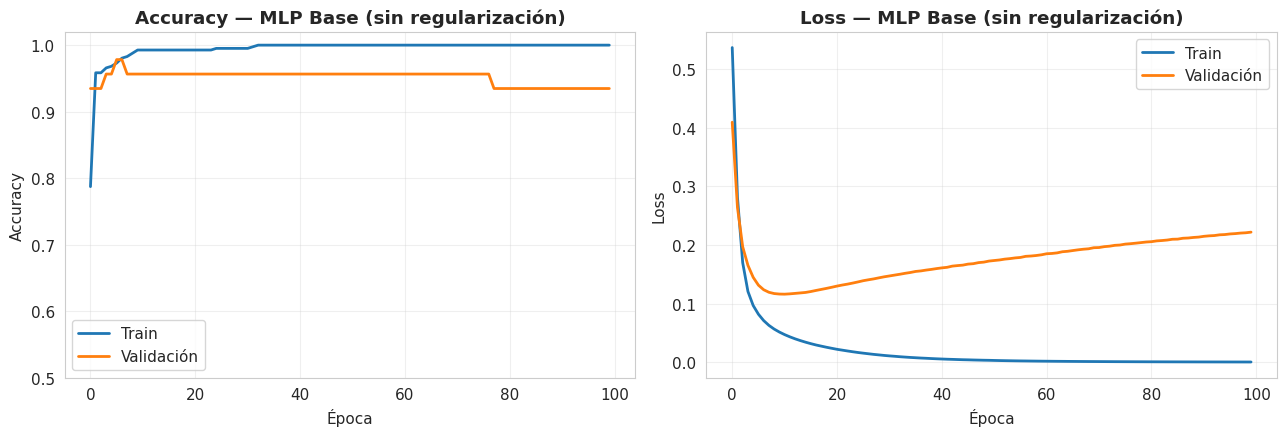

  Train acc: 1.0000 | Val acc: 0.9348 | Brecha: 0.0652
  ⚠️  Posible OVERFITTING (brecha > 5%)


In [9]:
# ============================================================
# 2.1 EVALUACIÓN SIMPLE — Curvas de aprendizaje
# ============================================================
# Las curvas muestran cómo evolucionaron accuracy y loss durante el entrenamiento.
# Si la curva de train sigue mejorando pero la de val se estanca o empeora → OVERFITTING.
graficar_historia(history_base, 'MLP Base (sin regularización)')


EVALUACIÓN — MLP Base
              precision    recall  f1-score   support

     Maligno     0.8723    0.9762    0.9213        42
     Benigno     0.9851    0.9167    0.9496        72

    accuracy                         0.9386       114
   macro avg     0.9287    0.9464    0.9355       114
weighted avg     0.9435    0.9386    0.9392       114



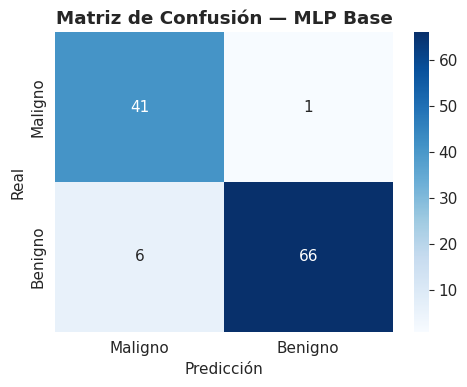

In [10]:
# ============================================================
# 2.2 EVALUACIÓN RIGUROSA — Métricas detalladas
# ============================================================
# Evaluamos en el conjunto de TEST (nunca visto durante el entrenamiento)
y_pred_prob_base, y_pred_base = evaluar_completo(
    model_base, X_test, y_test, 'MLP Base'
)

# --- Interpretación de la matriz de confusión ---
# En diagnóstico médico:
#   - Falso Negativo (FN) = predecir Benigno cuando es Maligno → MUY PELIGROSO
#   - Falso Positivo (FP) = predecir Maligno cuando es Benigno → genera alarma innecesaria
# El RECALL de la clase Maligno es la métrica más crítica en este contexto

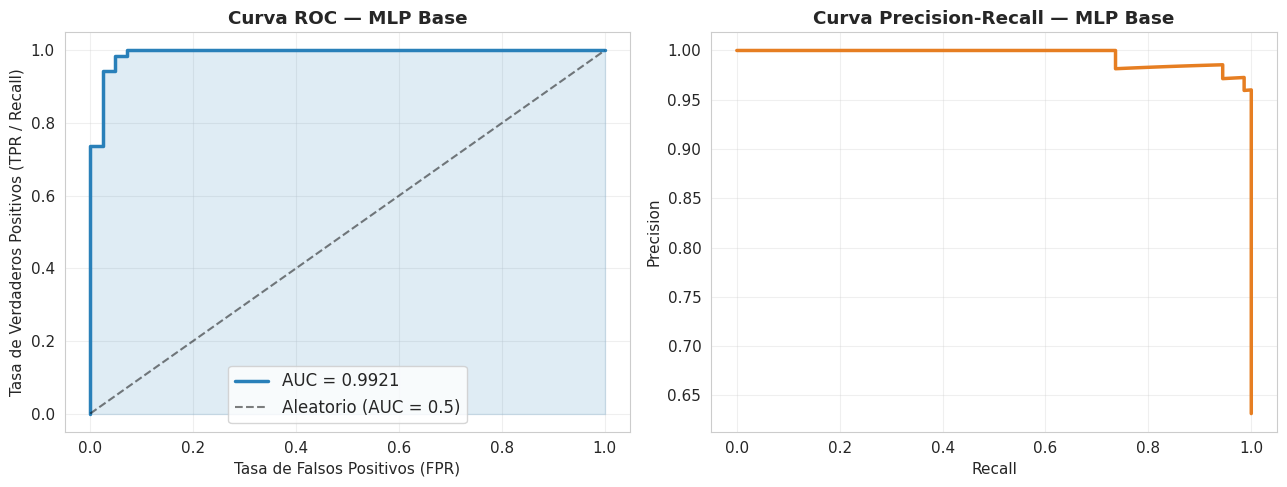

AUC-ROC: 0.9921
  > 0.90: excelente | 0.80-0.90: bueno | 0.70-0.80: aceptable | < 0.70: insuficiente


In [11]:
# ============================================================
# 2.3 CURVA ROC Y AUC
# ============================================================
# ROC mide la capacidad del modelo de separar las dos clases
# AUC = 1.0 → separación perfecta; AUC = 0.5 → clasificador aleatorio

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob_base)
roc_auc = auc(fpr, tpr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- Curva ROC ---
ax1.plot(fpr, tpr, color='#2980b9', linewidth=2.5, label=f'AUC = {roc_auc:.4f}')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio (AUC = 0.5)')
ax1.fill_between(fpr, tpr, alpha=0.15, color='#2980b9')
ax1.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax1.set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
ax1.set_title('Curva ROC — MLP Base', fontweight='bold')
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3)

# --- Curva Precision-Recall ---
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob_base)
ax2.plot(recall, precision, color='#e67e22', linewidth=2.5)
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Curva Precision-Recall — MLP Base', fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"AUC-ROC: {roc_auc:.4f}")
print(f"  > 0.90: excelente | 0.80-0.90: bueno | 0.70-0.80: aceptable | < 0.70: insuficiente")

Validación cruzada con K=5 folds:
----------------------------------------
  Fold 1: accuracy = 0.9560
  Fold 2: accuracy = 1.0000
  Fold 3: accuracy = 0.9780
  Fold 4: accuracy = 0.9890
  Fold 5: accuracy = 0.9780

  Promedio:   0.9802
  Desv. std:  0.0146
  Rango:      [0.9560, 1.0000]


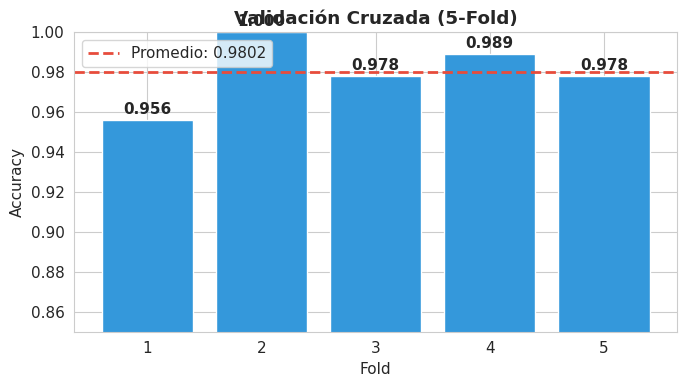

In [12]:
# ============================================================
# 2.4 VALIDACIÓN CRUZADA K-FOLD
# ============================================================
# La validación cruzada con K pliegues (folds) evalúa la estabilidad del modelo.
# En vez de depender de UNA sola partición train/val, entrenamos K veces
# con diferentes particiones y promediamos los resultados.

# Recombinamos train + val para hacer K-Fold sobre todo el conjunto no-test
X_trainval = np.vstack([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

K = 5
kfold = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
cv_scores = []

print(f"Validación cruzada con K={K} folds:")
print("-" * 40)

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_trainval, y_trainval), 1):
    # Creamos un modelo NUEVO para cada fold (pesos inicializados de cero)
    model_cv = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(30,)),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model_cv.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Entrenamos con early stopping para no overfittear
    model_cv.fit(
        X_trainval[train_idx], y_trainval[train_idx],
        epochs=100, batch_size=32,
        validation_data=(X_trainval[val_idx], y_trainval[val_idx]),
        callbacks=[callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
        verbose=0
    )

    _, acc = model_cv.evaluate(X_trainval[val_idx], y_trainval[val_idx], verbose=0)
    cv_scores.append(acc)
    print(f"  Fold {fold}: accuracy = {acc:.4f}")

print(f"\n  Promedio:   {np.mean(cv_scores):.4f}")
print(f"  Desv. std:  {np.std(cv_scores):.4f}")
print(f"  Rango:      [{min(cv_scores):.4f}, {max(cv_scores):.4f}]")

# Visualización
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(range(1, K+1), cv_scores, color='#3498db', edgecolor='white')
ax.axhline(y=np.mean(cv_scores), color='#e74c3c', linestyle='--',
           linewidth=2, label=f'Promedio: {np.mean(cv_scores):.4f}')
ax.set_xlabel('Fold'); ax.set_ylabel('Accuracy')
ax.set_title('Validación Cruzada (5-Fold)', fontweight='bold')
ax.set_ylim([0.85, 1.0])
ax.legend(fontsize=11)
for bar, score in zip(bars, cv_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{score:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

---
## BLOQUE 3 — Optimización y Regularización

El modelo base probablemente muestra **overfitting** (train acc ≫ val acc). Este bloque explora:

1. **Optimización:** efecto de distintos optimizadores y learning rates
2. **Regularización:** técnicas para reducir el sobreajuste
   - **L2 (weight decay):** penaliza pesos grandes
   - **Dropout:** desactiva neuronas al azar durante el entrenamiento
   - **Batch Normalization:** normaliza las activaciones entre capas
   - **Early Stopping:** detiene el entrenamiento cuando val_loss empeora

In [13]:
# ============================================================
# 3.1 COMPARACIÓN DE OPTIMIZADORES
# ============================================================
# Probamos los 3 optimizadores más utilizados:
#   - SGD: el clásico gradiente descendente estocástico
#   - Adam: combina momentum + RMSprop — el más popular
#   - RMSprop: divide LR por la raíz del promedio de gradientes al cuadrado

def crear_modelo_base():
    """Fábrica de modelos idénticos para comparación justa."""
    model = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(30,)),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

optimizers_config = {
    'SGD (lr=0.01)': tf.keras.optimizers.SGD(learning_rate=0.01),
    'SGD + Momentum': tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSprop': tf.keras.optimizers.RMSprop(learning_rate=0.001),
    'Adam': tf.keras.optimizers.Adam(learning_rate=0.001),
}

historias_opt = {}
for name, opt in optimizers_config.items():
    print(f"Entrenando con {name}...", end=' ')
    model = crear_modelo_base()
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    h = model.fit(X_train, y_train, batch_size=32, epochs=60,
                  validation_data=(X_val, y_val), verbose=0)
    historias_opt[name] = h
    print(f"val_acc = {h.history['val_accuracy'][-1]:.4f}")

print("\n✅ Comparación completada.")

Entrenando con SGD (lr=0.01)... val_acc = 0.9565
Entrenando con SGD + Momentum... val_acc = 0.9565
Entrenando con RMSprop... val_acc = 0.9565
Entrenando con Adam... val_acc = 0.9565

✅ Comparación completada.


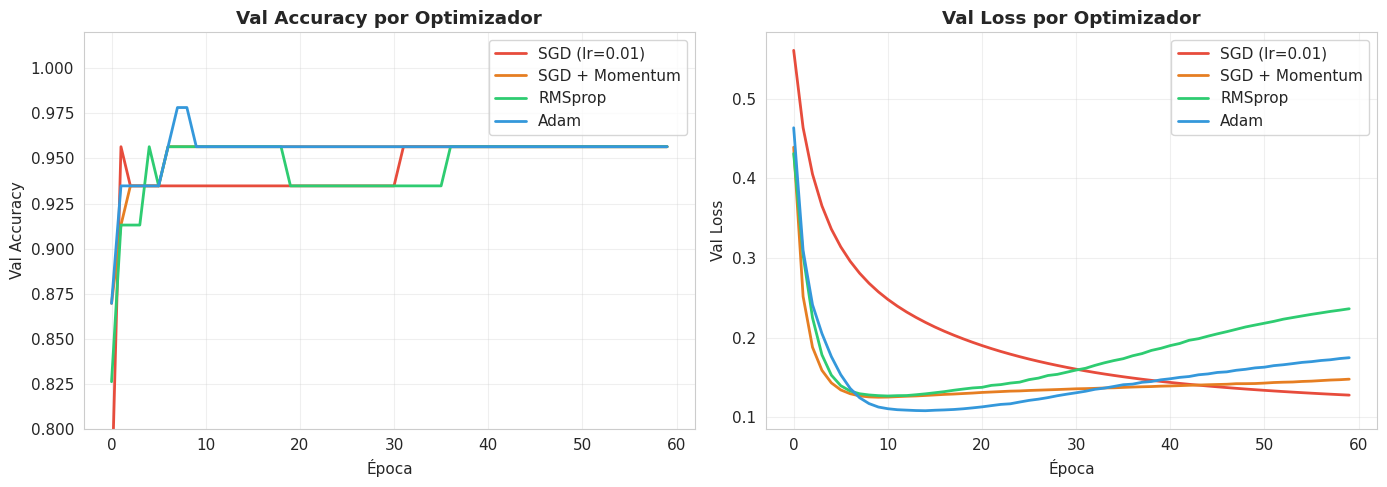

Observaciones:
  • SGD sin momentum converge lento pero puede generalizar mejor
  • Adam converge rápido, pero puede overfittear si no se regulariza
  • SGD + Momentum ofrece un buen equilibrio velocidad/estabilidad


In [14]:
# ============================================================
# VISUALIZACIÓN: COMPARACIÓN DE OPTIMIZADORES
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors_opt = ['#e74c3c', '#e67e22', '#2ecc71', '#3498db']

for (name, h), color in zip(historias_opt.items(), colors_opt):
    ax1.plot(h.history['val_accuracy'], label=name, linewidth=2, color=color)
    ax2.plot(h.history['val_loss'], label=name, linewidth=2, color=color)

ax1.set_title('Val Accuracy por Optimizador', fontweight='bold')
ax1.set_xlabel('Época'); ax1.set_ylabel('Val Accuracy')
ax1.legend(); ax1.grid(True, alpha=0.3); ax1.set_ylim([0.8, 1.02])

ax2.set_title('Val Loss por Optimizador', fontweight='bold')
ax2.set_xlabel('Época'); ax2.set_ylabel('Val Loss')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Observaciones:")
print("  • SGD sin momentum converge lento pero puede generalizar mejor")
print("  • Adam converge rápido, pero puede overfittear si no se regulariza")
print("  • SGD + Momentum ofrece un buen equilibrio velocidad/estabilidad")

LR = 0.1... val_acc = 0.9783
LR = 0.01... val_acc = 0.9348
LR = 0.001... val_acc = 0.9565
LR = 0.0001... val_acc = 0.9565


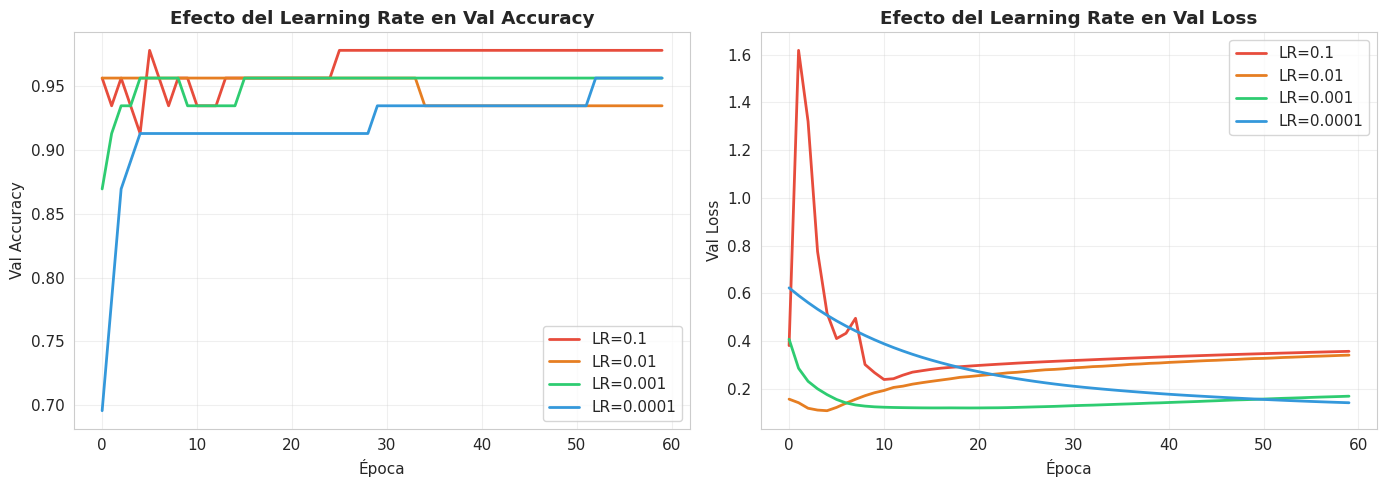

In [15]:
# ============================================================
# 3.2 EFECTO DEL LEARNING RATE
# ============================================================
# El learning rate (tasa de aprendizaje) es el hiperparámetro MÁS importante.
#   - Muy alto → el modelo oscila y no converge
#   - Muy bajo → el modelo converge pero muy lento
#   - Adecuado → convergencia rápida y estable

learning_rates = [0.1, 0.01, 0.001, 0.0001]
historias_lr = {}

for lr in learning_rates:
    print(f"LR = {lr}...", end=' ')
    model = crear_modelo_base()
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=['accuracy'])
    h = model.fit(X_train, y_train, batch_size=32, epochs=60,
                  validation_data=(X_val, y_val), verbose=0)
    historias_lr[f'LR={lr}'] = h
    print(f"val_acc = {h.history['val_accuracy'][-1]:.4f}")

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors_lr = ['#e74c3c', '#e67e22', '#2ecc71', '#3498db']

for (name, h), color in zip(historias_lr.items(), colors_lr):
    ax1.plot(h.history['val_accuracy'], label=name, linewidth=2, color=color)
    ax2.plot(h.history['val_loss'], label=name, linewidth=2, color=color)

ax1.set_title('Efecto del Learning Rate en Val Accuracy', fontweight='bold')
ax1.set_xlabel('Época'); ax1.set_ylabel('Val Accuracy')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.set_title('Efecto del Learning Rate en Val Loss', fontweight='bold')
ax2.set_xlabel('Época'); ax2.set_ylabel('Val Loss')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# 3.3 TÉCNICAS DE REGULARIZACIÓN — Comparación
# ============================================================
# Creamos 4 modelos, cada uno con UNA técnica de regularización diferente,
# para aislar el efecto de cada una.

def crear_modelo_l2(lam=0.01):
    """MLP con regularización L2 (weight decay) en todas las capas."""
    return models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(30,),
                     kernel_regularizer=regularizers.l2(lam)),
        layers.Dense(32, activation='relu',
                     kernel_regularizer=regularizers.l2(lam)),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_L2')

def crear_modelo_dropout(rate=0.3):
    """MLP con Dropout después de cada capa oculta."""
    return models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(30,)),
        layers.Dropout(rate),  # Desactiva 30% de las neuronas al azar
        layers.Dense(32, activation='relu'),
        layers.Dropout(rate),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_Dropout')

def crear_modelo_batchnorm():
    """MLP con Batch Normalization entre cada capa."""
    return models.Sequential([
        layers.Dense(64, use_bias=False, input_shape=(30,)),  # Sin bias (BN lo absorbe)
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dense(32, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dense(1, activation='sigmoid')
    ], name='MLP_BatchNorm')

# --- Entrenar cada variante ---
modelos_reg = {
    'Sin regularización': crear_modelo_base(),
    'L2 (λ=0.01)': crear_modelo_l2(0.01),
    'Dropout (0.3)': crear_modelo_dropout(0.3),
    'BatchNorm': crear_modelo_batchnorm(),
}

historias_reg = {}
for name, model in modelos_reg.items():
    print(f"Entrenando {name}...", end=' ')
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    h = model.fit(X_train, y_train, batch_size=32, epochs=100,
                  validation_data=(X_val, y_val), verbose=0)
    historias_reg[name] = h
    brecha = h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    print(f"val_acc={h.history['val_accuracy'][-1]:.4f}, brecha={brecha:.4f}")

Entrenando Sin regularización... val_acc=0.9348, brecha=0.0652
Entrenando L2 (λ=0.01)... val_acc=0.9565, brecha=0.0361
Entrenando Dropout (0.3)... val_acc=0.9783, brecha=0.0217
Entrenando BatchNorm... val_acc=0.9565, brecha=0.0435


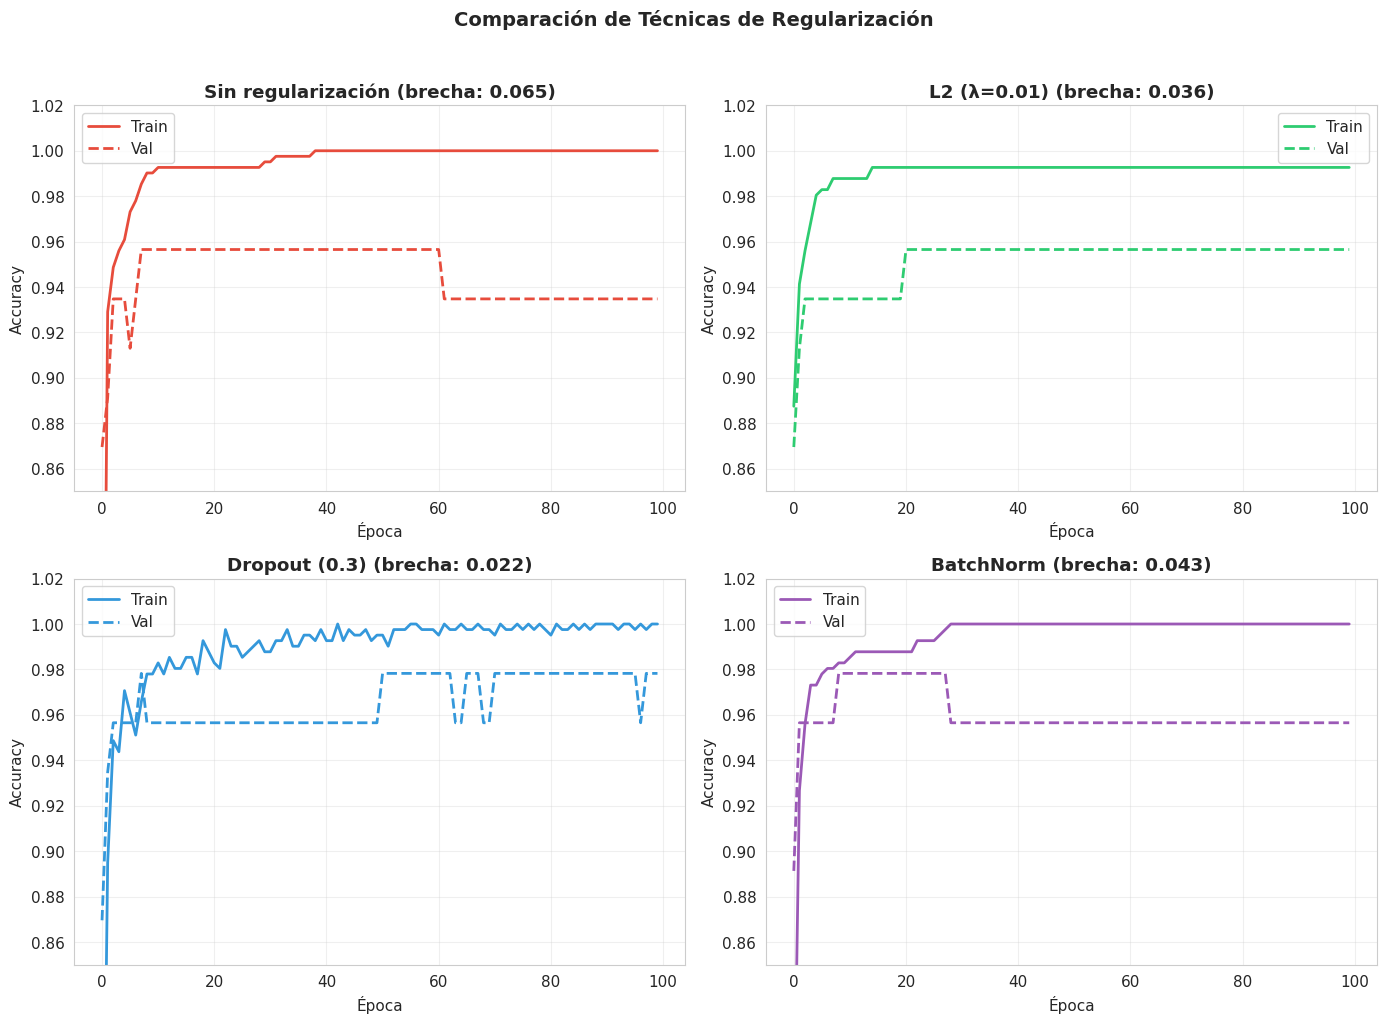

Resumen de brechas train-val (menor = mejor generalización):
  Sin regularización       : 0.0652
  L2 (λ=0.01)              : 0.0361
  Dropout (0.3)            : 0.0217
  BatchNorm                : 0.0435


In [17]:
# ============================================================
# VISUALIZACIÓN: EFECTO DE CADA REGULARIZACIÓN
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors_reg = ['#e74c3c', '#2ecc71', '#3498db', '#9b59b6']

for ax, (name, h), color in zip(axes.flat, historias_reg.items(), colors_reg):
    ax.plot(h.history['accuracy'], label='Train', linewidth=2, color=color)
    ax.plot(h.history['val_accuracy'], label='Val', linewidth=2, color=color, linestyle='--')
    brecha = h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    ax.set_title(f'{name} (brecha: {brecha:.3f})', fontweight='bold')
    ax.set_xlabel('Época'); ax.set_ylabel('Accuracy')
    ax.legend(); ax.grid(True, alpha=0.3)
    ax.set_ylim([0.85, 1.02])

plt.suptitle('Comparación de Técnicas de Regularización', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Resumen de brechas train-val (menor = mejor generalización):")
for name, h in historias_reg.items():
    brecha = h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    print(f"  {name:25s}: {brecha:.4f}")

In [18]:
# ============================================================
# 3.4 MODELO ÓPTIMO — Combinando todas las técnicas
# ============================================================
# Combinamos: BatchNorm + Dropout + L2 + EarlyStopping + ReduceLROnPlateau

model_optimo = models.Sequential([
    # Capa 1: Dense → BN → ReLU → Dropout
    layers.Dense(128, use_bias=False, input_shape=(30,),
                 kernel_regularizer=regularizers.l2(1e-4),
                 kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.3),

    # Capa 2
    layers.Dense(64, use_bias=False,
                 kernel_regularizer=regularizers.l2(1e-4),
                 kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.2),

    # Capa 3
    layers.Dense(32, use_bias=False,
                 kernel_regularizer=regularizers.l2(1e-4),
                 kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),

    # Salida
    layers.Dense(1, activation='sigmoid')
], name='MLP_Optimo')

# Callbacks avanzados
callbacks_optimo = [
    # Detiene si val_loss no mejora en 20 épocas
    callbacks.EarlyStopping(
        monitor='val_loss', patience=20,
        restore_best_weights=True, verbose=1
    ),
    # Reduce el LR a la mitad si val_loss se estanca 7 épocas
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=7, min_lr=1e-6, verbose=1
    ),
]

model_optimo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_optimo.summary()

Model: "MLP_Optimo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_51 (Dense)                │ (None, 128)            │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,009 (58.63 KB)

 Trainable params: 14,561 (56.88 KB)

 Non-trainable params: 448 (1.75 KB)


Epoch 39: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 46: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 52: early stopping
Restoring model weights from the end of the best epoch: 32.


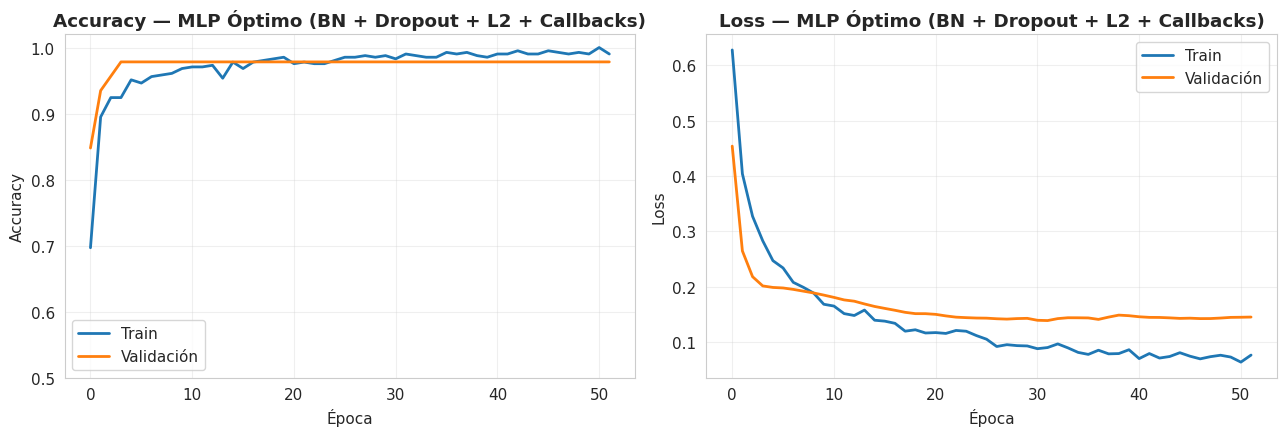

  Train acc: 0.9902 | Val acc: 0.9783 | Brecha: 0.0120
  ✅ Buen ajuste

EVALUACIÓN — MLP Óptimo
              precision    recall  f1-score   support

     Maligno     0.9302    0.9524    0.9412        42
     Benigno     0.9718    0.9583    0.9650        72

    accuracy                         0.9561       114
   macro avg     0.9510    0.9554    0.9531       114
weighted avg     0.9565    0.9561    0.9562       114



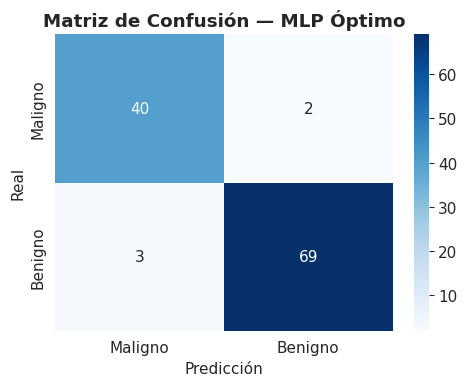

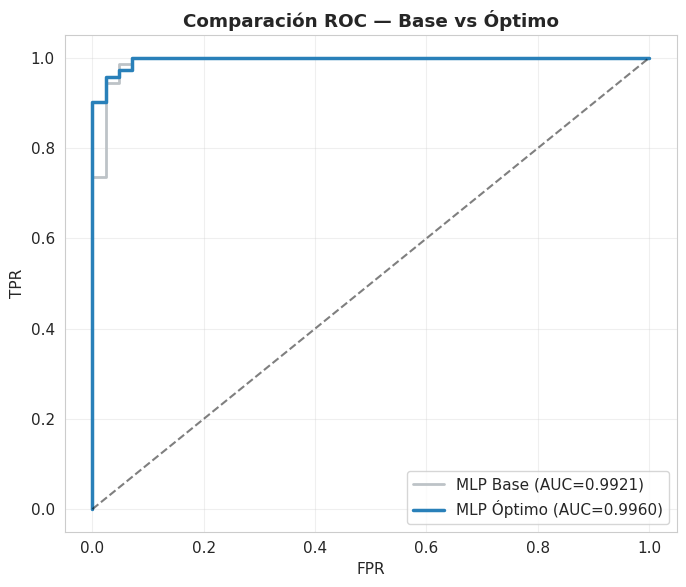

In [19]:
# ============================================================
# ENTRENAR Y EVALUAR MODELO ÓPTIMO
# ============================================================
history_optimo = model_optimo.fit(
    X_train, y_train,
    batch_size=32,
    epochs=200,
    validation_data=(X_val, y_val),
    callbacks=callbacks_optimo,
    verbose=0
)

# Curvas
graficar_historia(history_optimo, 'MLP Óptimo (BN + Dropout + L2 + Callbacks)')

# Evaluación en test
y_pred_prob_opt, y_pred_opt = evaluar_completo(
    model_optimo, X_test, y_test, 'MLP Óptimo'
)

# Comparar ROC
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_pred_prob_opt)
roc_auc_opt = auc(fpr_opt, tpr_opt)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='#bdc3c7', linewidth=2, label=f'MLP Base (AUC={roc_auc:.4f})')
ax.plot(fpr_opt, tpr_opt, color='#2980b9', linewidth=2.5, label=f'MLP Óptimo (AUC={roc_auc_opt:.4f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('Comparación ROC — Base vs Óptimo', fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## BLOQUE 4 — Interpretabilidad y Explicabilidad

Un modelo de alta accuracy no es útil si no podemos entender POR QUÉ toma sus decisiones. Esto es especialmente crítico en medicina, donde el diagnóstico debe ser justificable.

Exploramos tres niveles de interpretabilidad:
1. **Pesos de la primera capa** — ¿qué features reciben mayor importancia?
2. **Permutation Importance** — ¿qué features, al ser perturbadas, más afectan la accuracy?
3. **SHAP** — ¿cómo contribuye CADA feature a CADA predicción individual?

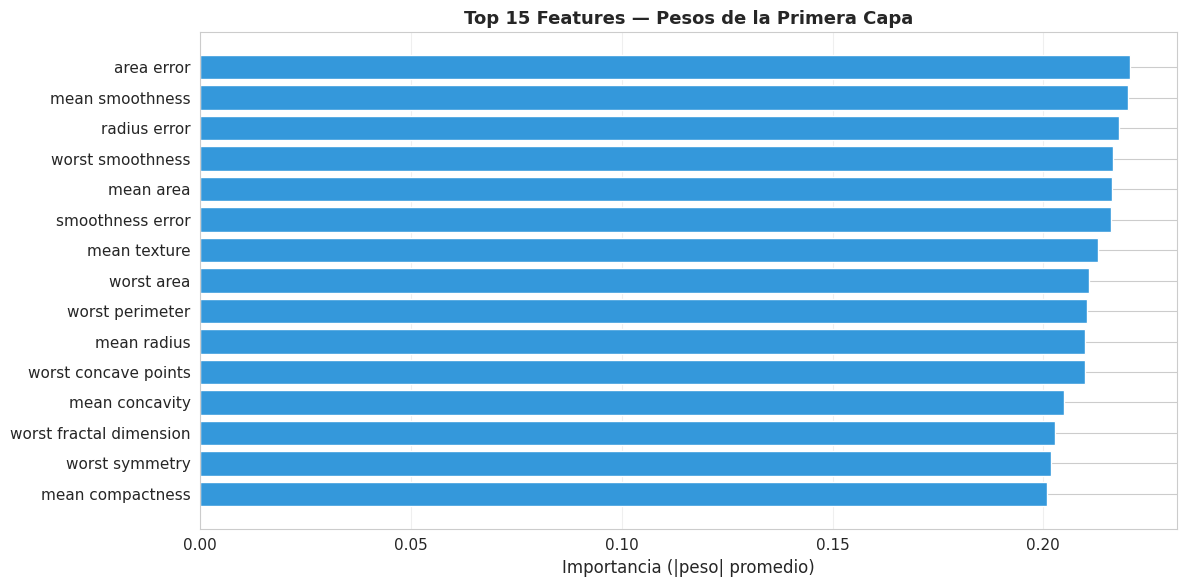

⚠️  Limitación: los pesos reflejan la magnitud de conexión, no causalidad.
    Features estandarizadas hacen esta comparación más justa.


In [20]:
# ============================================================
# 4.1 ANÁLISIS DE PESOS DE LA PRIMERA CAPA
# ============================================================
# Los pesos de la primera capa conectan cada feature de entrada con las
# neuronas de la capa oculta. Features con pesos grandes (en valor absoluto)
# tienden a ser más influyentes.

# Obtenemos los pesos de la primera capa densa
# (en el modelo óptimo, la primera capa con pesos es Dense(128))
primera_capa = None
for layer in model_optimo.layers:
    if isinstance(layer, layers.Dense) and layer.get_weights():
        primera_capa = layer
        break

weights = primera_capa.get_weights()[0]  # shape: (30, 128)

# Importancia = promedio del valor absoluto de los pesos por cada feature
importancia_pesos = np.mean(np.abs(weights), axis=1)  # shape: (30,)

# Ordenar de mayor a menor
indices = np.argsort(importancia_pesos)[::-1]

fig, ax = plt.subplots(figsize=(12, 6))
top_n = 15
ax.barh(range(top_n), importancia_pesos[indices[:top_n]][::-1],
        color='#3498db', edgecolor='white')
ax.set_yticks(range(top_n))
ax.set_yticklabels([feature_names[i] for i in indices[:top_n]][::-1])
ax.set_xlabel('Importancia (|peso| promedio)', fontsize=12)
ax.set_title('Top 15 Features — Pesos de la Primera Capa', fontweight='bold', fontsize=13)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("⚠️  Limitación: los pesos reflejan la magnitud de conexión, no causalidad.")
print("    Features estandarizadas hacen esta comparación más justa.")

Calculando permutation importance (esto puede tardar ~30 seg)...


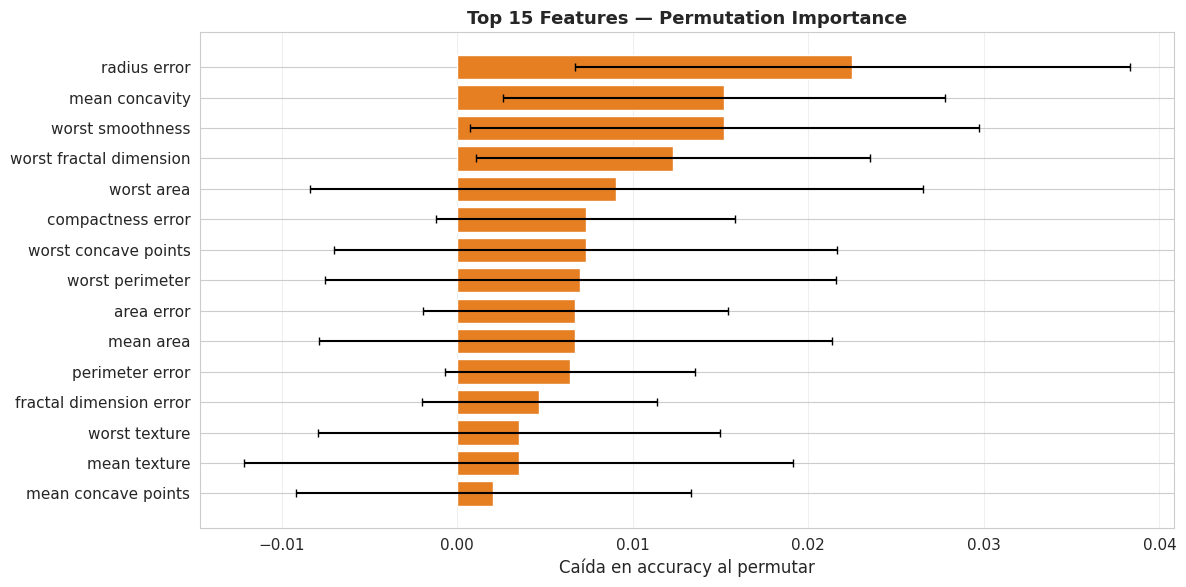


Top 5 features más críticas:
  1. radius error                   Δacc = 0.0225 ± 0.0158
  2. mean concavity                 Δacc = 0.0152 ± 0.0126
  3. worst smoothness               Δacc = 0.0152 ± 0.0145
  4. worst fractal dimension        Δacc = 0.0123 ± 0.0112
  5. worst area                     Δacc = 0.0091 ± 0.0175


In [22]:
# ============================================================
# 4.2 PERMUTATION IMPORTANCE
# ============================================================
# Idea: permutar (desordenar) los valores de UNA feature a la vez y medir
# cuánto EMPEORA la accuracy. Cuanto más empeora, más importante es esa feature.
# Ventaja: es model-agnostic (funciona con cualquier modelo)

from sklearn.base import BaseEstimator

# Necesitamos envolver el modelo Keras para que sklearn pueda usarlo
class KerasClassifierWrapper(BaseEstimator):
    """Wrapper para usar modelo Keras con sklearn permutation_importance."""
    def __init__(self, model):
        self.model = model
    def fit(self, X, y=None):
        # El modelo ya está entrenado, por lo que no es necesario ajustar nada
        return self
    def predict(self, X):
        return (self.model.predict(X, verbose=0).flatten() >= 0.5).astype(int)
    def score(self, X, y):
        return accuracy_score(y, self.predict(X))

wrapper = KerasClassifierWrapper(model_optimo)

# Calcular permutation importance en el conjunto de test
print("Calculando permutation importance (esto puede tardar ~30 seg)...")
perm_result = permutation_importance(
    wrapper, X_test, y_test,
    n_repeats=30,      # Repetimos 30 veces por estabilidad
    random_state=SEED,
    scoring='accuracy'
)

# Ordenar por importancia
perm_sorted = perm_result.importances_mean.argsort()[::-1]

fig, ax = plt.subplots(figsize=(12, 6))
top_n = 15
idx = perm_sorted[:top_n][::-1]
ax.barh(range(top_n),
        perm_result.importances_mean[idx],
        xerr=perm_result.importances_std[idx],
        color='#e67e22', edgecolor='white', capsize=3)
ax.set_yticks(range(top_n))
ax.set_yticklabels([feature_names[i] for i in idx])
ax.set_xlabel('Caída en accuracy al permutar', fontsize=12)
ax.set_title('Top 15 Features — Permutation Importance', fontweight='bold', fontsize=13)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\nTop 5 features más críticas:")
for i in range(5):
    j = perm_sorted[i]
    print(f"  {i+1}. {feature_names[j]:30s} Δacc = {perm_result.importances_mean[j]:.4f} ± {perm_result.importances_std[j]:.4f}")

In [23]:
# ============================================================
# 4.3 SHAP — Explicaciones Individuales y Globales
# ============================================================
# SHAP (SHapley Additive exPlanations) descompone CADA predicción en la
# contribución de CADA feature. Basado en teoría de juegos (valores de Shapley).

# Seleccionamos un subconjunto del training para crear el explicador
# (100 muestras de fondo — más es más preciso pero más lento)
background = X_train[:100]

# DeepExplainer es optimizado para redes neuronales
try:
    explainer = shap.DeepExplainer(model_optimo, background)
    shap_values = explainer.shap_values(X_test[:100])
    print("✅ SHAP DeepExplainer ejecutado correctamente.")
except Exception as e:
    print(f"DeepExplainer falló ({e}). Usando KernelExplainer (más lento)...")
    explainer = shap.KernelExplainer(
        lambda x: model_optimo.predict(x, verbose=0).flatten(),
        background
    )
    shap_values = explainer.shap_values(X_test[:50])
    print("✅ SHAP KernelExplainer ejecutado correctamente.")

✅ SHAP DeepExplainer ejecutado correctamente.


<Figure size 1200x800 with 0 Axes>

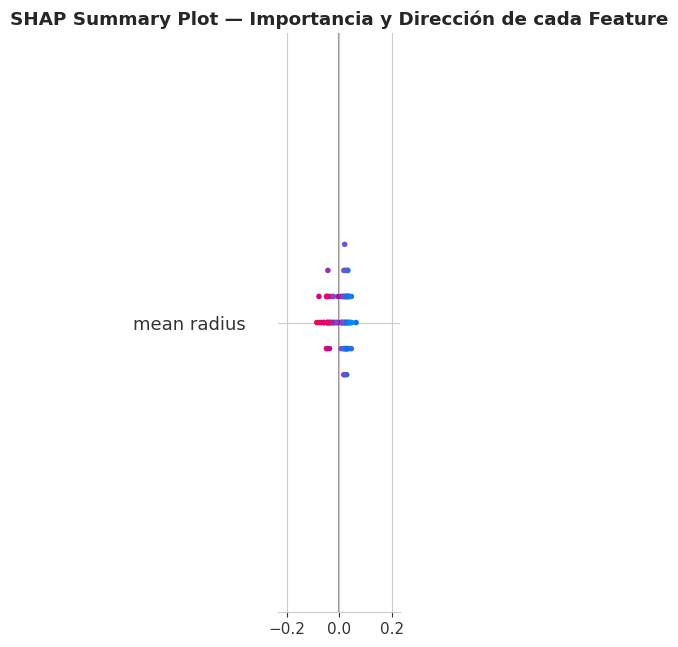

In [24]:
# ============================================================
# SHAP — Gráfico de resumen global (Summary Plot)
# ============================================================
# Este gráfico muestra:
#   - Eje Y: features ordenadas por importancia global
#   - Eje X: valor SHAP (contribución a la predicción)
#   - Color: valor de la feature (rojo=alto, azul=bajo)
# Si una feature roja (valor alto) tiene SHAP positivo → valores altos
# de esa feature empujan la predicción hacia la clase positiva (benigno)

# Manejamos el formato de shap_values (puede ser lista o array)
sv = shap_values[0] if isinstance(shap_values, list) else shap_values
n_samples = sv.shape[0]

plt.figure(figsize=(12, 8))
shap.summary_plot(
    sv,
    X_test[:n_samples],
    feature_names=feature_names,
    show=False
)
plt.title('SHAP Summary Plot — Importancia y Dirección de cada Feature', fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

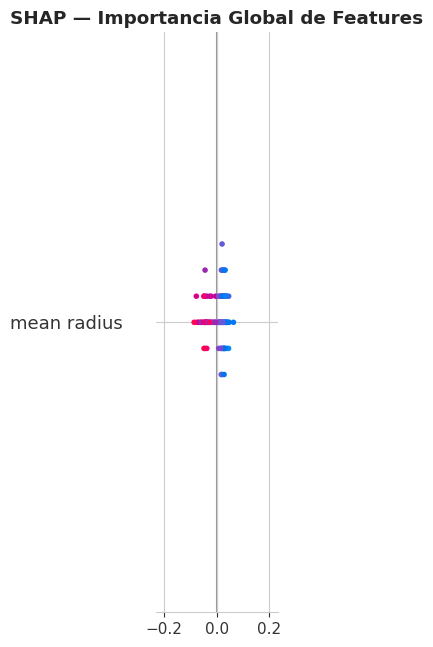

In [25]:
# ============================================================
# SHAP — Importancia global (Bar Plot)
# ============================================================
plt.figure(figsize=(10, 6))
shap.summary_plot(
    sv,
    X_test[:n_samples],
    feature_names=feature_names,
    plot_type='bar',
    show=False
)
plt.title('SHAP — Importancia Global de Features', fontweight='bold')
plt.tight_layout()
plt.show()

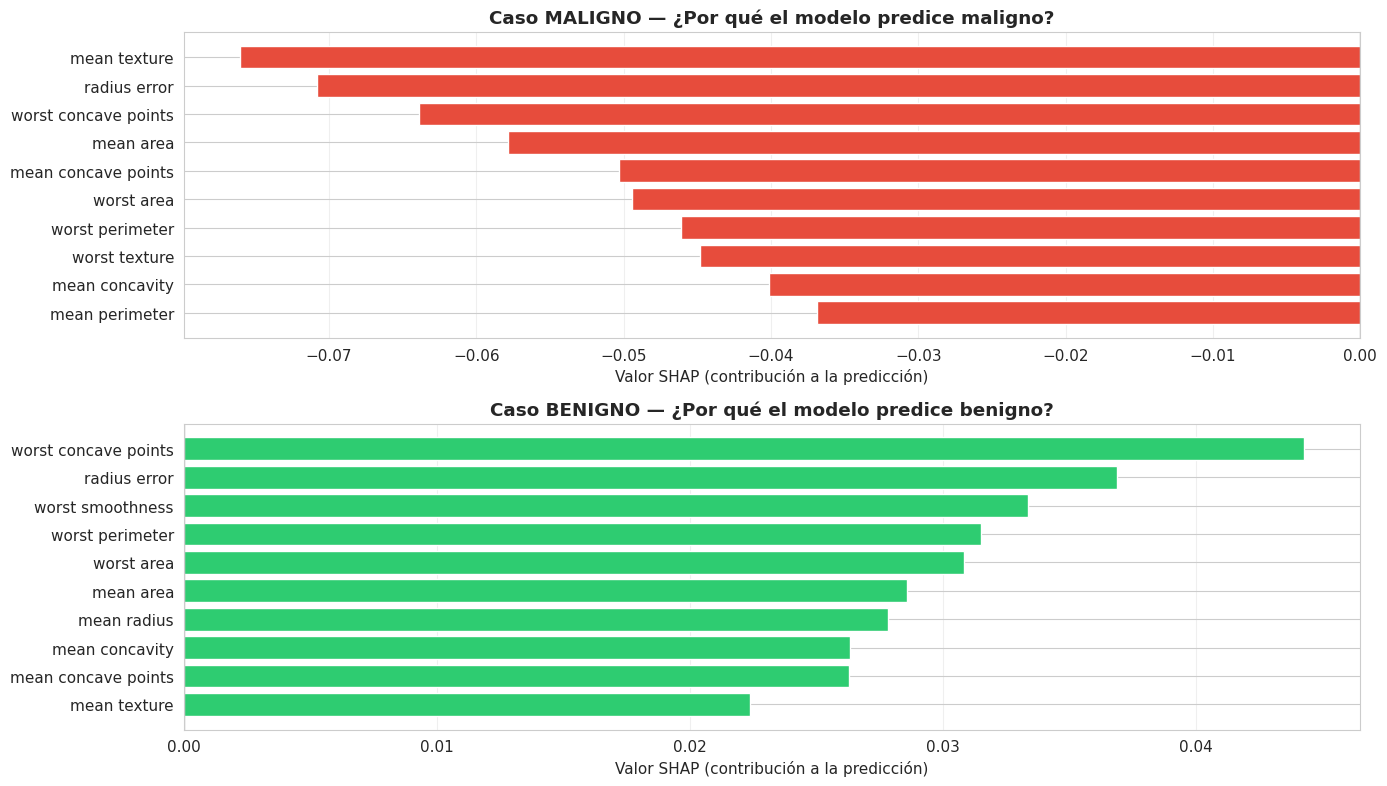

Interpretación:
  🔴 Rojo: la feature empuja la predicción hacia MALIGNO
  🟢 Verde: la feature empuja la predicción hacia BENIGNO


In [27]:
# ============================================================
# SHAP — Explicación de predicciones individuales
# ============================================================
# Analizamos DOS casos concretos: un tumor maligno y uno benigno

# Encontrar un ejemplo de cada clase en el test set
idx_maligno = np.where(y_test == 0)[0][0]
idx_benigno = np.where(y_test == 1)[0][0]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for i, (idx, titulo) in enumerate([
    (idx_maligno, 'Caso MALIGNO — ¿Por qué el modelo predice maligno?'),
    (idx_benigno, 'Caso BENIGNO — ¿Por qué el modelo predice benigno?')
]):
    if idx < n_samples:
        sv_i = sv[idx].flatten()  # Agregamos .flatten() para evitar dimensiones extra (30, 1) -> (30,)
    else:
        sv_i = sv[0].flatten()  # fallback

    # Top 10 features que más influyeron en esta predicción
    top_idx = np.argsort(np.abs(sv_i))[::-1][:10]
    colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in sv_i[top_idx]]

    axes[i].barh(range(10), sv_i[top_idx][::-1], color=colors[::-1])
    axes[i].set_yticks(range(10))
    axes[i].set_yticklabels([feature_names[j] for j in top_idx][::-1])
    axes[i].set_xlabel('Valor SHAP (contribución a la predicción)')
    axes[i].set_title(titulo, fontweight='bold')
    axes[i].axvline(x=0, color='black', linewidth=0.8)
    axes[i].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print("Interpretación:")
print("  🔴 Rojo: la feature empuja la predicción hacia MALIGNO")
print("  🟢 Verde: la feature empuja la predicción hacia BENIGNO")

In [29]:
# ============================================================
# 4.4 COMPARACIÓN DE MÉTODOS DE INTERPRETABILIDAD
# ============================================================
# ¿Los tres métodos coinciden en las features más importantes?

# Extraer top 10 de cada método
top_pesos = [str(feature_names[i]) for i in np.argsort(importancia_pesos)[::-1][:10]]
top_perm = [str(feature_names[i]) for i in perm_sorted[:10]]

# sv tiene dimensiones (N, 30, 1), por lo que calculamos el promedio absoluto colapsando la dimensión residual
mean_shap = np.mean(np.abs(sv), axis=0).flatten()
top_shap = [str(feature_names[i]) for i in np.argsort(mean_shap)[::-1][:10]]

print("="*70)
print(f"{'Rango':<6} {'Pesos 1ra capa':<25} {'Permutation':<25} {'SHAP':<25}")
print("="*70)
for i in range(10):
    print(f"{i+1:<6} {top_pesos[i]:<25} {top_perm[i]:<25} {top_shap[i]:<25}")

# Features que aparecen en los 3 rankings
comunes = set(top_pesos) & set(top_perm) & set(top_shap)
print(f"\n✅ Features en los 3 rankings: {comunes if comunes else 'Ninguna'}")
print(f"\n📊 Nota: la concordancia entre métodos aumenta la confianza en la interpretación.")
print(f"   Discrepancias sugieren que el modelo usa interacciones complejas entre features.")

Rango  Pesos 1ra capa            Permutation               SHAP                     
1      area error                radius error              worst concave points     
2      mean smoothness           mean concavity            radius error             
3      radius error              worst smoothness          mean area                
4      worst smoothness          worst fractal dimension   mean texture             
5      mean area                 worst area                worst smoothness         
6      smoothness error          compactness error         worst area               
7      mean texture              worst concave points      mean radius              
8      worst area                worst perimeter           worst perimeter          
9      worst perimeter           area error                worst texture            
10     mean radius               mean area                 mean concavity           

✅ Features en los 3 rankings: {'worst smoothness', 'worst perime

---
## BLOQUE 5 — Síntesis y Comparación Final


TABLA COMPARATIVA FINAL — TODOS LOS MODELOS
             Modelo  Params  Test Acc     F1  Brecha
 Sin regularización    4097    0.9561 0.9645  0.0652
        L2 (λ=0.01)    4097    0.9737 0.9790  0.0361
      Dropout (0.3)    4097    0.9561 0.9645  0.0217
          BatchNorm    4385    0.9912 0.9931  0.0435
✅ MLP Óptimo (todo)   15009    0.9561 0.9650  0.0120


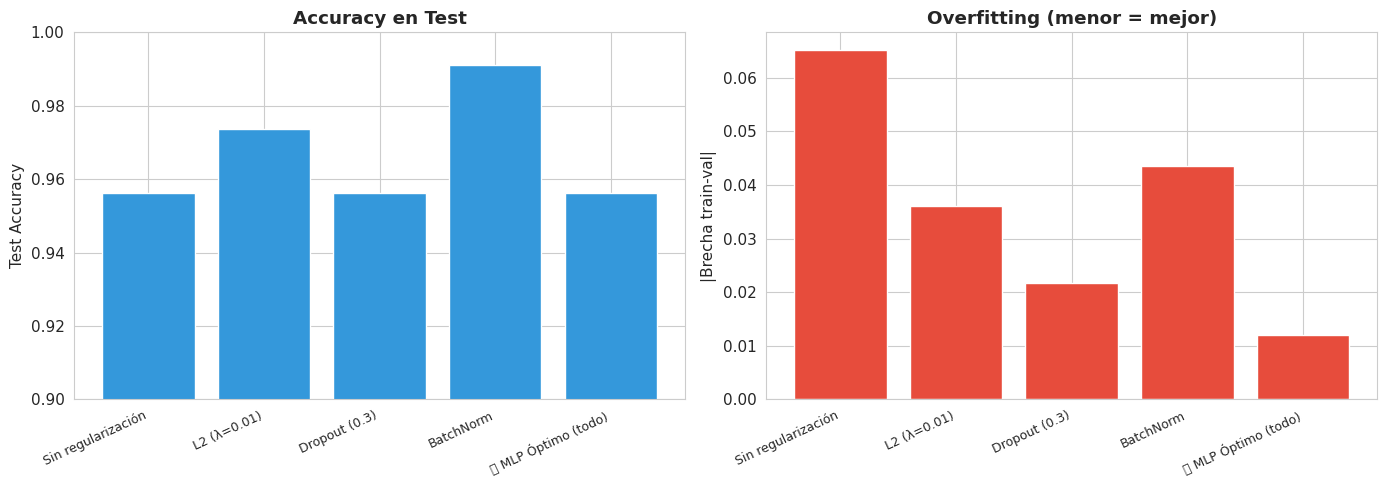

In [30]:
# ============================================================
# TABLA COMPARATIVA FINAL
# ============================================================
# Evaluamos todos los modelos de regularización en test
resultados = []

for name, model in modelos_reg.items():
    y_p = (model.predict(X_test, verbose=0).flatten() >= 0.5).astype(int)
    acc = accuracy_score(y_test, y_p)
    f1 = f1_score(y_test, y_p)
    params = model.count_params()
    h = historias_reg[name]
    brecha = h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    resultados.append({'Modelo': name, 'Params': params, 'Test Acc': acc,
                       'F1': f1, 'Brecha': brecha})

# Modelo óptimo
y_p_opt = (model_optimo.predict(X_test, verbose=0).flatten() >= 0.5).astype(int)
acc_opt = accuracy_score(y_test, y_p_opt)
f1_opt = f1_score(y_test, y_p_opt)
brecha_opt = history_optimo.history['accuracy'][-1] - history_optimo.history['val_accuracy'][-1]
resultados.append({'Modelo': '✅ MLP Óptimo (todo)', 'Params': model_optimo.count_params(),
                   'Test Acc': acc_opt, 'F1': f1_opt, 'Brecha': brecha_opt})

df_resultados = pd.DataFrame(resultados)
print("\n" + "="*75)
print("TABLA COMPARATIVA FINAL — TODOS LOS MODELOS")
print("="*75)
print(df_resultados.to_string(index=False, float_format='%.4f'))

# Gráfico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x = range(len(df_resultados))
nombres = df_resultados['Modelo'].tolist()

ax1.bar(x, df_resultados['Test Acc'], color='#3498db', edgecolor='white')
ax1.set_xticks(x)
ax1.set_xticklabels(nombres, rotation=25, ha='right', fontsize=9)
ax1.set_ylabel('Test Accuracy')
ax1.set_title('Accuracy en Test', fontweight='bold')
ax1.set_ylim([0.9, 1.0])

ax2.bar(x, df_resultados['Brecha'].abs(), color='#e74c3c', edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels(nombres, rotation=25, ha='right', fontsize=9)
ax2.set_ylabel('|Brecha train-val|')
ax2.set_title('Overfitting (menor = mejor)', fontweight='bold')

plt.tight_layout()
plt.show()

---
## Conclusiones

### Evaluación
- La **accuracy sola** puede ser engañosa, especialmente con clases desbalanceadas.
- La **matriz de confusión** revela los tipos de errores (FP vs FN), cruciales en contextos como diagnóstico médico.
- La **curva ROC** y el **AUC** resumen la capacidad discriminativa del modelo independientemente del umbral.
- La **validación cruzada K-Fold** evalúa la estabilidad y robustez del modelo.

### Optimización y Regularización
- **Adam** es un buen punto de partida, pero puede overfittear rápidamente en datasets pequeños.
- **Dropout**, **L2** y **Batch Normalization** reducen el overfitting de maneras complementarias.
- **EarlyStopping** y **ReduceLROnPlateau** son indispensables para un entrenamiento eficiente.
- La combinación de todas las técnicas produce el modelo más robusto.

### Interpretabilidad
- **Pesos de la primera capa:** rápido pero limitado (solo refleja la magnitud de las conexiones).
- **Permutation Importance:** model-agnostic y confiable, mide impacto real en el rendimiento.
- **SHAP:** el estándar de oro — explica cada predicción individual y revela direccionalidad.
- La **concordancia entre métodos** fortalece la confianza en las conclusiones.

---

*Notebook Versión A — Redes Neuronales Densas (MLP) | ISO56B | UNCP*